In [11]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
# Load the Uber fares dataset
data = pd.read_csv("uber.csv")
print(data.shape)
data.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
# Remove unnecessary columns and prepare the dataset
data = data.drop(columns=["key", "Unnamed: 0"], errors="ignore")
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"], errors="coerce", utc=True)
data = data.dropna(subset=[
    "fare_amount", "pickup_datetime", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count"
])

data = data[
    (data["fare_amount"] > 0) &
    (data["pickup_longitude"].between(-180, 180)) &
    (data["dropoff_longitude"].between(-180, 180)) &
    (data["pickup_latitude"].between(-90, 90)) &
    (data["dropoff_latitude"].between(-90, 90)) &
    (data["pickup_longitude"] != 0) &
    (data["pickup_latitude"] != 0) &
    (data["dropoff_longitude"] != 0) &
    (data["dropoff_latitude"] != 0) &
    (data["passenger_count"].between(1, 6))
].copy()

data.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
# Create date and time features
data["pickup_hour"] = data["pickup_datetime"].dt.hour
data["pickup_day"] = data["pickup_datetime"].dt.day
data["pickup_month"] = data["pickup_datetime"].dt.month
data["pickup_weekday"] = data["pickup_datetime"].dt.dayofweek

In [5]:
# Calculate trip distance using the Haversine formula
lat1 = np.radians(data["pickup_latitude"])
lat2 = np.radians(data["dropoff_latitude"])
lon1 = np.radians(data["pickup_longitude"])
lon2 = np.radians(data["dropoff_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1
a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
data["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
data = data[data["distance_km"] > 0].copy()

data[["fare_amount", "distance_km"]].head()

,fare_amount,distance_km
0,7.5,1.683323
1,7.7,2.457590
2,12.9,5.036377
3,5.3,1.661683
4,16.0,4.475450


In [6]:
# Identify outliers using the IQR method
def get_iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

fare_low, fare_high = get_iqr_bounds(data["fare_amount"])
distance_low, distance_high = get_iqr_bounds(data["distance_km"])

fare_outliers = ~data["fare_amount"].between(fare_low, fare_high)
distance_outliers = ~data["distance_km"].between(distance_low, distance_high)

print("Fare outliers:", fare_outliers.sum())
print("Distance outliers:", distance_outliers.sum())
print("Rows before removing outliers:", len(data))

data = data[
    data["fare_amount"].between(fare_low, fare_high) &
    data["distance_km"].between(distance_low, distance_high)
].copy()

print("Rows after removing outliers:", len(data))

Fare outliers: 16548
Distance outliers: 16089
Rows before removing outliers: 193270
Rows after removing outliers: 173750


fare_amount          1.000000
distance_km          0.817186
pickup_month         0.029480
pickup_weekday       0.017867
passenger_count      0.015634
pickup_day           0.006156
dropoff_longitude    0.002916
pickup_longitude     0.002295
pickup_hour         -0.002843
pickup_latitude     -0.003219
dropoff_latitude    -0.003584
Name: fare_amount, dtype: float64


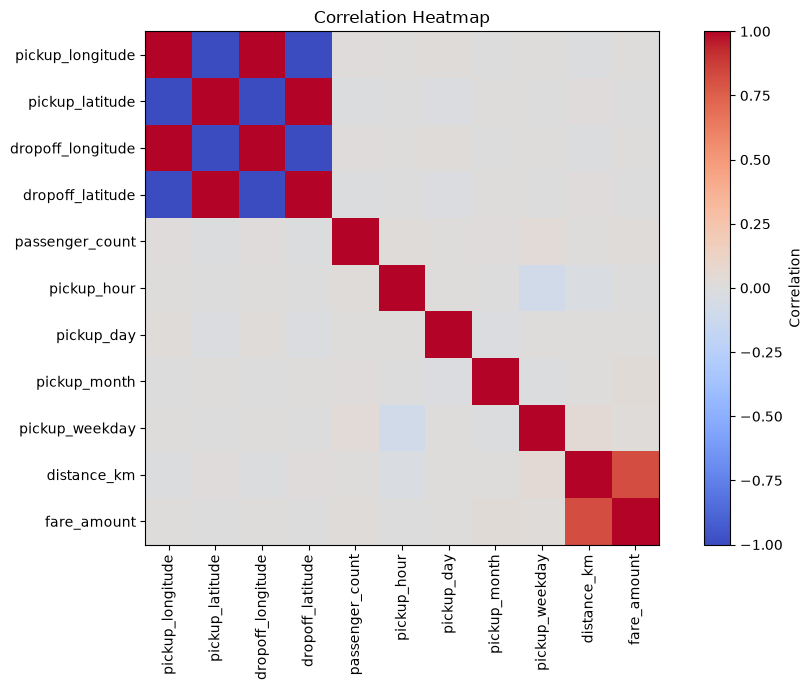

In [7]:
# Check feature correlations
features = [
    "pickup_longitude", "pickup_latitude", "dropoff_longitude",
    "dropoff_latitude", "passenger_count", "pickup_hour", "pickup_day",
    "pickup_month", "pickup_weekday", "distance_km"
]
correlation = data[features + ["fare_amount"]].corr()
print(correlation["fare_amount"].sort_values(ascending=False))

plt.figure(figsize=(10, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [8]:
# Split the data into input features and target
X = data[features]
y = data["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
# Train linear regression, Ridge, and Lasso models
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso Regression": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000))
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

results_df = pd.DataFrame(results)
results_df

,Model,R2 Score,RMSE
0,Linear Regression,0.661123,2.306202
1,Ridge Regression,0.661095,2.306297
2,Lasso Regression,0.657524,2.318413


            Model  R2 Score     RMSE
Linear Regression  0.661123 2.306202
 Ridge Regression  0.661095 2.306297
 Lasso Regression  0.657524 2.318413


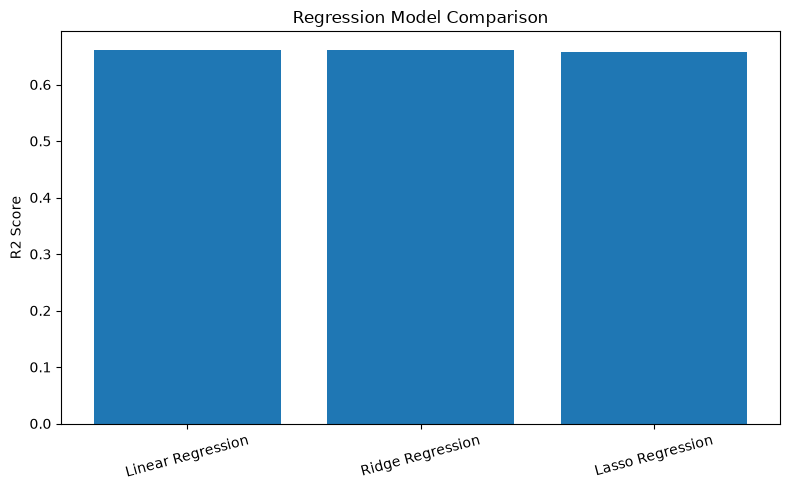

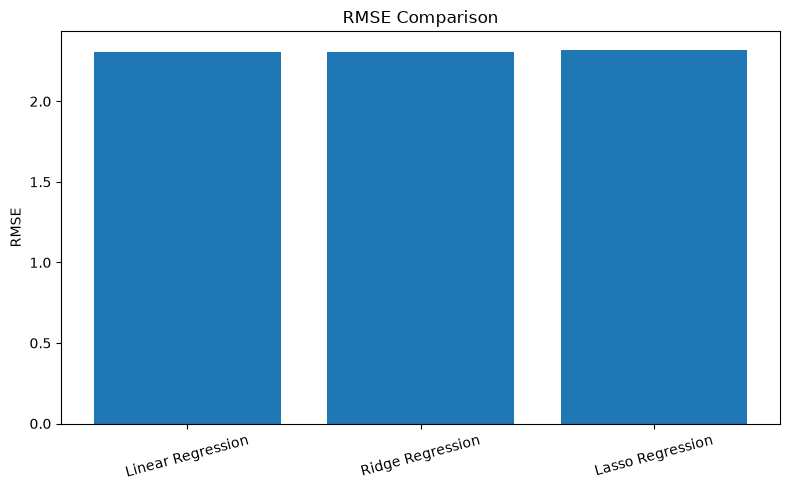

In [10]:
# Compare model R2 scores and RMSE values
print(results_df.sort_values("R2 Score", ascending=False).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.ylabel("R2 Score")
plt.title("Regression Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE")
plt.title("RMSE Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()